# 04 · Modelización

**Objetivo:** encontrar el mejor modelo para estimar el salario de un trabajador a partir de su perfil y convertirlo en un **rango salarial fiable** (P10, P50 y P90), que es lo que mostrará la web.

**Plan del notebook**
1. Definir cómo se mide la calidad de un modelo.
2. Comparar modelos de complejidad creciente: referencias simples → regresión lineal → Random Forest → LightGBM.
3. Ajustar los hiperparámetros del mejor modelo con Optuna.
4. Comprobar tres decisiones de diseño: separar por empresa, usar los pesos de la encuesta y simplificar las variables para la web.
5. Construir el modelo final de **rango salarial** con regresión cuantílica y **calibración conformal**.
6. Analizar dónde se equivoca el modelo.

Todos los modelos se entrenan con el conjunto de **entrenamiento** de 2022 y se evalúan con el de **prueba**, formado por empresas que el modelo no ha visto (notebook 03). El código reutilizable está en `src/modelos.py`.

### Preparación del entorno

Funciona tanto en local (abriendo el notebook dentro del repositorio clonado) como en **Google Colab**: si se abre en Colab sin el repositorio, lo descarga de GitHub automáticamente y, si hacen falta, pide subir los microdatos del INE.

In [1]:
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/alfredobrocalserrano/tfm-salarios-ees"
EN_COLAB = "google.colab" in sys.modules


def buscar_raiz():
    """Devuelve la carpeta del proyecto (la que contiene src/) o None si no está."""
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        if (carpeta / "src").is_dir():
            return carpeta
    return None


RAIZ = buscar_raiz()
if RAIZ is None:
    if EN_COLAB:
        RAIZ = Path("/content/tfm-salarios-ees")
        if not RAIZ.exists():
            print("Descargando el repositorio del proyecto...")
            subprocess.run(["git", "clone", "-q", REPO_URL, str(RAIZ)], check=True)
    else:
        raise FileNotFoundError(
            "No se encuentra la carpeta src/ del proyecto. Clona el repositorio "
            f"({REPO_URL}) y abre el notebook desde dentro (ver README)."
        )

sys.path.insert(0, str(RAIZ))
print("Carpeta del proyecto:", RAIZ)

Carpeta del proyecto: /home/claude/tfm-salarios-ees


In [2]:
# Solo en Colab: si no está el dataset procesado ni los microdatos del INE, se piden para subirlos
if EN_COLAB and not (RAIZ / "data" / "processed" / "ees_2018_2022.parquet").exists():
    from google.colab import files

    carpeta_raw = RAIZ / "data" / "raw"
    carpeta_raw.mkdir(parents=True, exist_ok=True)
    faltan = [a for a in (2018, 2022) if not (carpeta_raw / f"md_EES_{a}.parquet").exists()]
    if faltan:
        print("Sube los ficheros:", ", ".join(f"md_EES_{a}.parquet" for a in faltan))
        for nombre, contenido in files.upload().items():
            for anio in faltan:
                if str(anio) in nombre and nombre.endswith(".parquet"):
                    (carpeta_raw / f"md_EES_{anio}.parquet").write_bytes(contenido)
                    print("Guardado:", f"md_EES_{anio}.parquet")

In [3]:
import importlib
import time
import warnings

for paquete in ["lightgbm", "optuna"]:  # por si el entorno (p. ej. Colab) no los trae instalados
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)

import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import optuna
import pandas as pd
import seaborn as sns

from src.estadistica import cuantil_ponderado, mediana_ponderada
from src.preparacion import (
    OBJETIVO, PESO, VARIABLES_APP, VARIABLES_MODELO, cargar_conjuntos, dividir_por_empresa,
)
from src.modelos import (
    PARAMETROS_LGBM, ModeloRangoSalarial, cobertura, crear_lgbm, crear_random_forest, crear_ridge, metricas,
)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", font_scale=0.95)
EUROS = mticker.FuncFormatter(lambda x, _: f"{x:,.0f} €".replace(",", "."))
AZUL, ROJO, GRIS = "#3B6EA5", "#C0392B", "#7F8C8D"

conjuntos = cargar_conjuntos()
train, test = conjuntos["train_2022"], conjuntos["test_2022"]
X_train, y_train, w_train = train[VARIABLES_MODELO], train[OBJETIVO], train[PESO]
X_test, y_test, w_test = test[VARIABLES_MODELO], test[OBJETIVO], test[PESO]
print(f"Entrenamiento: {len(train):,} registros | Prueba: {len(test):,} registros")

Entrenamiento: 188,419 registros | Prueba: 46,768 registros


## 1. Cómo se mide la calidad

Los modelos predicen el logaritmo del salario, pero lo que importa al usuario son los **euros**. Se usan cuatro métricas, todas **ponderadas** con `FACTOTAL` para que representen al conjunto de asalariados:

| Métrica | Qué significa | Mejor si... |
|---|---|---|
| **R²** | Parte de la variabilidad del (log) salario que explica el modelo | más alto (máx. 1) |
| **MAE (€)** | Error medio en euros | más bajo |
| **Error mediano (%)** | La mitad de las predicciones se equivoca menos que este porcentaje | más bajo |
| **% a menos del 20 %** | Proporción de predicciones con un error inferior al 20 % | más alto |

El **error mediano (%)** es la métrica más fácil de explicar a negocio: *"en la mitad de los casos el modelo acierta el salario con un margen menor del X %"*.

In [4]:
resultados = {}

def evaluar(nombre, prediccion_log, segundos=None):
    fila = metricas(y_test, prediccion_log, w_test)
    if segundos is not None:
        fila["Tiempo de entrenamiento (s)"] = segundos
    resultados[nombre] = fila
    return pd.Series(fila).round(3)

## 2. Modelos de referencia

Antes de usar modelos complejos hay que saber cuánto aporta cada uno frente a algo trivial:
- **Referencia 1:** predecir siempre el salario típico (la misma cifra para todo el mundo).
- **Referencia 2:** una regla de negocio sencilla: el salario mediano de la **ocupación** de la persona. Es lo que haría alguien con una tabla publicada del INE.

In [5]:
evaluar("Referencia: salario típico", np.full(len(test), np.average(y_train, weights=w_train)))

mediana_ocupacion = train.groupby("ocupacion", observed=True).apply(
    lambda g: np.log(mediana_ponderada(np.exp(g[OBJETIVO]), g[PESO])), include_groups=False)
prediccion_regla = test["ocupacion"].map(mediana_ocupacion).astype(float).fillna(np.average(y_train, weights=w_train))
evaluar("Referencia: mediana de la ocupación", prediccion_regla)

pd.DataFrame(resultados).T.round(3)

,R²,MAE (€),Error mediano (%),% a menos del 20 %
Referencia: salario típico,-0.001,11561.324,35.703,29.760
Referencia: mediana de la ocupación,0.235,9521.418,27.700,38.613


## 3. Regresión lineal regularizada (Ridge)

Es el modelo clásico de la economía laboral (la *ecuación de Mincer*): cada característica suma o resta un porcentaje al salario. Las variables categóricas se convierten en indicadores (*one-hot*) y las numéricas (horas y antigüedad) en curvas suaves (*splines*), porque su efecto no es una línea recta. La regularización Ridge evita coeficientes inestables cuando hay variables relacionadas entre sí, como ocupación y estudios.

In [6]:
inicio = time.time()
ridge = crear_ridge().fit(X_train, y_train, ridge__sample_weight=w_train)
evaluar("Ridge (lineal)", ridge.predict(X_test), time.time() - inicio)

R²                                0.781
MAE (€)                        6232.348
Error mediano (%)                17.880
% a menos del 20 %               54.572
Tiempo de entrenamiento (s)       2.011
dtype: float64

## 4. Random Forest

Combina cientos de árboles de decisión entrenados con muestras distintas. A diferencia del modelo lineal, capta **interacciones** de forma automática (por ejemplo, que tener estudios superiores no vale lo mismo en todos los sectores).

In [7]:
inicio = time.time()
bosque = crear_random_forest().fit(X_train, y_train, randomforestregressor__sample_weight=w_train)
evaluar("Random Forest", bosque.predict(X_test), time.time() - inicio)

R²                                0.787
MAE (€)                        6029.304
Error mediano (%)                17.197
% a menos del 20 %               56.153
Tiempo de entrenamiento (s)       8.355
dtype: float64

## 5. LightGBM (gradient boosting)

En lugar de promediar árboles independientes, el *gradient boosting* construye árboles **en secuencia**: cada uno corrige los errores de los anteriores. LightGBM es una implementación muy eficiente que trabaja directamente con variables categóricas. Primero se prueba con una configuración estándar.

In [8]:
inicio = time.time()
lgbm_base = crear_lgbm(n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=40,
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.8)
lgbm_base.fit(X_train, y_train, sample_weight=w_train)
evaluar("LightGBM (configuración estándar)", lgbm_base.predict(X_test), time.time() - inicio)

R²                                0.813
MAE (€)                        5625.275
Error mediano (%)                15.804
% a menos del 20 %               60.020
Tiempo de entrenamiento (s)       5.421
dtype: float64

## 6. Ajuste de hiperparámetros con Optuna

Optuna busca la mejor combinación de hiperparámetros (número de hojas, ritmo de aprendizaje, regularización...) de forma inteligente: aprende de los intentos anteriores para proponer los siguientes.

Para no hacer trampa con el conjunto de prueba, la búsqueda usa una **validación interna**: el 20 % de las empresas de entrenamiento. Además, cada intento para de añadir árboles cuando deja de mejorar (*early stopping*). Se hacen 20 intentos (unos 2–3 minutos).

In [9]:
ajuste, validacion = dividir_por_empresa(train, 0.2, semilla=7)

def objetivo(trial):
    parametros = {
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.15, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 255, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 300, log=True),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "cat_smooth": trial.suggest_float("cat_smooth", 1, 50, log=True),
    }
    modelo = crear_lgbm(n_estimators=3000, subsample_freq=1, **parametros)
    modelo.fit(ajuste[VARIABLES_MODELO], ajuste[OBJETIVO], sample_weight=ajuste[PESO],
               eval_set=[(validacion[VARIABLES_MODELO], validacion[OBJETIVO])], eval_sample_weight=[validacion[PESO]],
               callbacks=[lgb.early_stopping(100, verbose=False)])
    trial.set_user_attr("n_arboles", modelo.best_iteration_)
    return modelo.best_score_["valid_0"]["l2"]

inicio = time.time()
estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
estudio.optimize(objetivo, n_trials=20)
print(f"Búsqueda completada en {time.time() - inicio:.0f} s")
mejores = {**estudio.best_params, "n_estimators": estudio.best_trial.user_attrs["n_arboles"], "subsample_freq": 1}
pd.Series(mejores).round(4).to_frame("mejor valor")

Búsqueda completada en 121 s


,mejor valor
learning_rate,0.0385
num_leaves,207.0000
min_child_samples,13.0000
colsample_bytree,0.4281
subsample,0.8681
reg_lambda,0.0092
cat_smooth,19.3596
n_estimators,393.0000
subsample_freq,1.0000


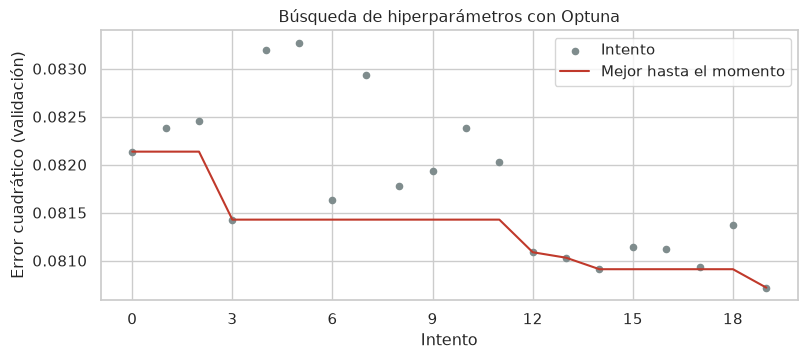

In [10]:
historial = estudio.trials_dataframe()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.scatter(historial["number"], historial["value"], color=GRIS, s=20, label="Intento")
ax.plot(historial["number"], historial["value"].cummin(), color=ROJO, label="Mejor hasta el momento")
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.set(title="Búsqueda de hiperparámetros con Optuna", xlabel="Intento", ylabel="Error cuadrático (validación)")
ax.legend()
plt.show()

In [11]:
inicio = time.time()
lgbm_ajustado = crear_lgbm(**mejores).fit(X_train, y_train, sample_weight=w_train)
evaluar("LightGBM (ajustado con Optuna)", lgbm_ajustado.predict(X_test), time.time() - inicio)

R²                                0.814
MAE (€)                        5620.598
Error mediano (%)                15.831
% a menos del 20 %               59.855
Tiempo de entrenamiento (s)       7.226
dtype: float64

## 7. Comparación de modelos

In [12]:
comparacion = pd.DataFrame(resultados).T
comparacion.round(3)

,R²,MAE (€),Error mediano (%),% a menos del 20 %,Tiempo de entrenamiento (s)
Referencia: salario típico,-0.001,11561.324,35.703,29.760,NaN
Referencia: mediana de la ocupación,0.235,9521.418,27.700,38.613,NaN
Ridge (lineal),0.781,6232.348,17.880,54.572,2.011
Random Forest,0.787,6029.304,17.197,56.153,8.355
LightGBM (configuración estándar),0.813,5625.275,15.804,60.020,5.421
LightGBM (ajustado con Optuna),0.814,5620.598,15.831,59.855,7.226


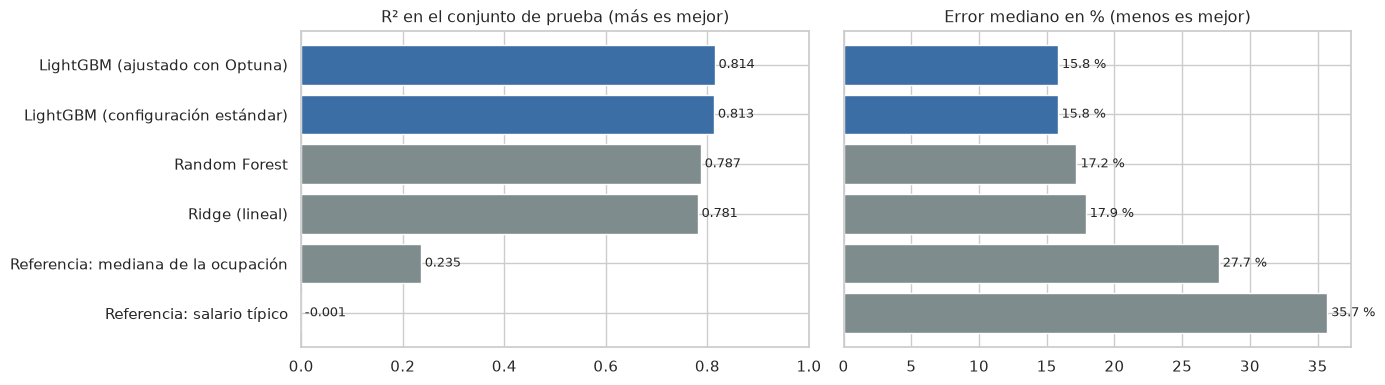

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
orden = comparacion.sort_values("R²").index
ax[0].barh(orden, comparacion.loc[orden, "R²"], color=[AZUL if "LightGBM" in m else GRIS for m in orden])
ax[0].set(title="R² en el conjunto de prueba (más es mejor)", xlim=(0, 1))
ax[1].barh(orden, comparacion.loc[orden, "Error mediano (%)"], color=[AZUL if "LightGBM" in m else GRIS for m in orden])
ax[1].set(title="Error mediano en % (menos es mejor)", yticklabels=[])
for eje, columna, formato in [(ax[0], "R²", "{:.3f}"), (ax[1], "Error mediano (%)", "{:.1f} %")]:
    for i, m in enumerate(orden):
        eje.text(comparacion.loc[m, columna], i, " " + formato.format(comparacion.loc[m, columna]), va="center", fontsize=9)
plt.tight_layout()
plt.show()

**Lectura de los resultados**
- La regla de negocio (salario mediano de la ocupación) ya mejora mucho a la referencia trivial, pero **los modelos que combinan todas las variables reducen el error a la mitad**.
- El modelo lineal funciona sorprendentemente bien: la mayor parte del salario se explica por efectos "aditivos" (en porcentaje) de cada característica.
- **LightGBM es el mejor en todas las métricas.** Su ventaja sobre el lineal viene de captar interacciones entre variables.
- **El ajuste con Optuna apenas mejora a LightGBM con una configuración razonable.** Es un resultado importante: el límite no lo pone el algoritmo, sino la información disponible. Dos personas con el mismo perfil en la encuesta pueden cobrar distinto por factores que no se observan (su desempeño, la empresa concreta, la negociación...). Por eso es más honesto dar un **rango** que una cifra exacta (sección 9).

**Modelo elegido:** LightGBM con los hiperparámetros ajustados. Para que el modelo final sea reproducible sin repetir la búsqueda, los hiperparámetros se fijan en `src/modelos.py` (`PARAMETROS_LGBM`). Proceden de una búsqueda más larga (30 intentos) hecha durante el desarrollo. Los valores concretos no coinciden con los de esta búsqueda, pero eso no importa: hay muchas combinaciones distintas que funcionan igual de bien, como confirma la segunda tabla.

In [14]:
pd.DataFrame({"Esta búsqueda": pd.Series(mejores), "Guardados en src/modelos.py": pd.Series(PARAMETROS_LGBM)}).round(4)

,Esta búsqueda,Guardados en src/modelos.py
cat_smooth,19.3596,30.9000
colsample_bytree,0.4281,0.6290
learning_rate,0.0385,0.0208
min_child_samples,13.0000,15.0000
n_estimators,393.0000,494.0000
num_leaves,207.0000,213.0000
reg_lambda,0.0092,0.0060
subsample,0.8681,0.5900
subsample_freq,1.0000,1.0000


In [15]:
lgbm_fijado = crear_lgbm(**PARAMETROS_LGBM).fit(X_train, y_train, sample_weight=w_train)
pd.DataFrame({
    "Esta búsqueda": resultados["LightGBM (ajustado con Optuna)"],
    "Guardados en src/modelos.py": metricas(y_test, lgbm_fijado.predict(X_test), w_test),
}).T.drop(columns="Tiempo de entrenamiento (s)", errors="ignore").round(3)

,R²,MAE (€),Error mediano (%),% a menos del 20 %
Esta búsqueda,0.814,5620.598,15.831,59.855
Guardados en src/modelos.py,0.815,5603.922,15.840,60.219


## 8. Tres decisiones de diseño, comprobadas

### 8.1 ¿Por qué separar entrenamiento y prueba por empresa?
Se repite el entrenamiento separando a los trabajadores **al azar**, sin respetar las empresas, como haría un análisis típico.

In [16]:
experimentos = {"Separación por empresa (la usada)": resultados["LightGBM (ajustado con Optuna)"]}

todos = pd.concat([train, test], ignore_index=True)
al_azar = np.random.RandomState(0).rand(len(todos)) < 0.8
modelo = crear_lgbm(**mejores).fit(todos.loc[al_azar, VARIABLES_MODELO], todos.loc[al_azar, OBJETIVO],
                                   sample_weight=todos.loc[al_azar, PESO])
experimentos["Separación al azar"] = metricas(todos.loc[~al_azar, OBJETIVO],
                                              modelo.predict(todos.loc[~al_azar, VARIABLES_MODELO]),
                                              todos.loc[~al_azar, PESO])
pd.DataFrame(experimentos).T.drop(columns="Tiempo de entrenamiento (s)", errors="ignore").round(3)

,R²,MAE (€),Error mediano (%),% a menos del 20 %
Separación por empresa (la usada),0.814,5620.598,15.831,59.855
Separación al azar,0.819,5451.563,14.560,62.849


Separando al azar, el modelo **parece** mejor, pero es un espejismo: los compañeros de una misma empresa comparten convenio y política salarial, y el modelo "reconoce" la empresa. En la web, el usuario siempre será de una empresa que el modelo no conoce, así que la evaluación por empresa es la realista.

### 8.2 ¿Hay que entrenar con los pesos de la encuesta?

In [17]:
sin_pesos = crear_lgbm(**mejores).fit(X_train, y_train)
pd.DataFrame({
    "Con pesos (FACTOTAL)": resultados["LightGBM (ajustado con Optuna)"],
    "Sin pesos": metricas(y_test, sin_pesos.predict(X_test), w_test),
}).T.drop(columns="Tiempo de entrenamiento (s)", errors="ignore").round(3)

,R²,MAE (€),Error mediano (%),% a menos del 20 %
Con pesos (FACTOTAL),0.814,5620.598,15.831,59.855
Sin pesos,0.816,5605.380,15.737,59.881


La diferencia es mínima. Se mantienen los pesos por coherencia: el objetivo es representar a la población de asalariados, no a la muestra (que sobrerrepresenta a las grandes empresas).

### 8.3 ¿Cuánto se pierde con las variables de la web?
La web no pregunta por el tipo de convenio ni por el mercado de la empresa (notebook 03).

In [18]:
modelo_web = crear_lgbm(**mejores).fit(train[VARIABLES_APP], y_train, sample_weight=w_train)
pd.DataFrame({
    f"Todas las variables ({len(VARIABLES_MODELO)})": resultados["LightGBM (ajustado con Optuna)"],
    f"Variables de la web ({len(VARIABLES_APP)})": metricas(y_test, modelo_web.predict(test[VARIABLES_APP]), w_test),
}).T.drop(columns="Tiempo de entrenamiento (s)", errors="ignore").round(3)

,R²,MAE (€),Error mediano (%),% a menos del 20 %
Todas las variables (16),0.814,5620.598,15.831,59.855
Variables de la web (14),0.807,5729.042,16.170,58.728


La pérdida es muy pequeña. **El modelo final usará solo las variables de la web**: un formulario más corto y comprensible compensa con creces esa mínima pérdida de precisión.

## 9. Modelo final: rango salarial

Una sola cifra transmite una precisión que el modelo no tiene. La web mostrará un **rango**: entre qué valores cobra el 80 % de las personas con ese perfil (del P10 al P90), además del valor central (P50, la mediana).

**Paso 1 · Regresión cuantílica.** En lugar de predecir la media, se entrenan tres modelos LightGBM que predicen directamente los percentiles 10, 50 y 90.

**Paso 2 · Calibración conformal.** Los modelos cuantílicos suelen dar intervalos algo estrechos: en teoría el 80 % de los salarios reales debería caer dentro, pero en la práctica caen menos. La **predicción conformal** (*Conformalized Quantile Regression*, Romano et al., 2019) lo corrige: se reserva un conjunto de **calibración** (empresas que el modelo no ha visto), se mide cuánto se sale del intervalo cada salario real, y se ensancha el intervalo lo justo para alcanzar el 80 %. Su ventaja es que ofrece una **garantía estadística** de cobertura sin suponer ninguna distribución concreta de los errores.

Todo esto está encapsulado en la clase `ModeloRangoSalarial` de `src/modelos.py`, que es la que usará la API.

In [19]:
inicio = time.time()
modelo_final = ModeloRangoSalarial(variables=VARIABLES_APP).entrenar(train)
print(f"Modelo final entrenado en {time.time() - inicio:.0f} s")
print(f"Ajuste conformal: ±{modelo_final.ajuste:.4f} en escala logarítmica "
      f"(el intervalo se ensancha un {100 * (np.exp(modelo_final.ajuste) - 1):.1f} % por cada lado)")

Modelo final entrenado en 37 s
Ajuste conformal: ±0.0440 en escala logarítmica (el intervalo se ensancha un 4.5 % por cada lado)


In [20]:
sin_calibrar = modelo_final._predecir_log(test)
calibrado = modelo_final.predecir_log(test)

pd.DataFrame({
    "Sin calibrar": {
        "Cobertura P10–P90 (%)": cobertura(y_test, sin_calibrar[0.10], sin_calibrar[0.90], w_test),
        "Anchura típica (P90 / P10)": np.median(np.exp(sin_calibrar[0.90] - sin_calibrar[0.10])),
    },
    "Calibrado (conformal)": {
        "Cobertura P10–P90 (%)": cobertura(y_test, calibrado["p10"], calibrado["p90"], w_test),
        "Anchura típica (P90 / P10)": np.median(np.exp(calibrado["p90"] - calibrado["p10"])),
    },
    "Objetivo": {"Cobertura P10–P90 (%)": 80.0, "Anchura típica (P90 / P10)": np.nan},
}).round(2)

,Sin calibrar,Calibrado (conformal),Objetivo
Cobertura P10–P90 (%),72.72,79.80,80.0
Anchura típica (P90 / P10),1.88,2.06,NaN


La cobertura calibrada se queda muy cerca del 80 % en empresas que el modelo nunca ha visto (sin calibrar, apenas pasaba del 72 %). Un intervalo con un P90 que duplica al P10 puede parecer ancho, pero refleja la realidad: personas con el mismo perfil observable cobran salarios muy distintos.

Una garantía global no basta: el rango debe ser fiable **para cada tipo de trabajador**, no solo de media.

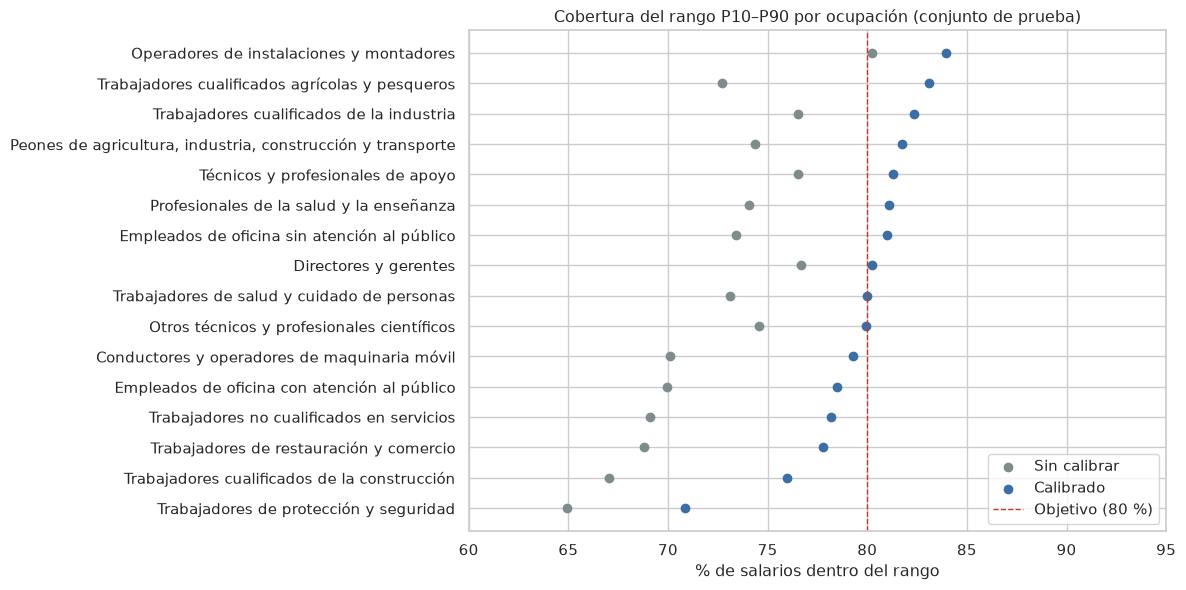

In [21]:
y = test[OBJETIVO].to_numpy()
cob = test.assign(
    sin_calibrar=((y >= sin_calibrar[0.10]) & (y <= sin_calibrar[0.90])).astype(float),
    calibrado=((y >= calibrado["p10"]) & (y <= calibrado["p90"])).astype(float),
)
por_ocupacion = cob.groupby("ocupacion", observed=True).apply(
    lambda g: pd.Series({c: 100 * np.average(g[c], weights=g[PESO]) for c in ["sin_calibrar", "calibrado"]}),
    include_groups=False).sort_values("calibrado")

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(por_ocupacion["sin_calibrar"], por_ocupacion.index, color=GRIS, label="Sin calibrar")
ax.scatter(por_ocupacion["calibrado"], por_ocupacion.index, color=AZUL, label="Calibrado")
ax.axvline(80, color=ROJO, ls="--", lw=1, label="Objetivo (80 %)")
ax.set(title="Cobertura del rango P10–P90 por ocupación (conjunto de prueba)", xlabel="% de salarios dentro del rango", xlim=(60, 95))
ax.legend(loc="lower right")
plt.show()

La calibración sube la cobertura en todas las ocupaciones y deja la mayoría entre el 76 % y el 84 %. La excepción es *Trabajadores de protección y seguridad* (en torno al 71 %), cuyos salarios en la prueba se alejan más de lo aprendido. La predicción conformal garantiza la cobertura **en promedio**, no dentro de cada grupo; por eso conviene revisarla por grupos, y se vigilará en la monitorización (notebook 06).

In [22]:
cob.groupby("jornada", observed=True).apply(
    lambda g: pd.Series({c: 100 * np.average(g[c], weights=g[PESO]) for c in ["sin_calibrar", "calibrado"]}),
    include_groups=False).round(1)

,sin_calibrar,calibrado
jornada,,
Tiempo completo,74.2,81.1
Tiempo parcial,67.7,75.4


En los contratos a tiempo parcial la cobertura es algo menor (en torno al 75 %): son el grupo más heterogéneo, porque mezcla jornadas de muy pocas horas con contratos de temporada (notebook 03). Se tendrá en cuenta al interpretar los rangos de ese grupo.

### 9.1 Ejemplos de perfiles

Así se verá el resultado en la web para cuatro perfiles inventados:

In [23]:
base = {"region": "Este", "sexo": "Mujer", "nacionalidad": "España", "contrato": "Indefinido",
        "control": "Privado", "responsabilidad": "Sin responsabilidad", "jornada": "Tiempo completo", "horas_semanales": 40.0}
perfiles = pd.DataFrame([
    {**base, "nombre": "Camarera, 20-29 años, media jornada", "ocupacion": "Trabajadores de restauración y comercio",
     "sector": "Hostelería", "estudios": "Secundaria 2ª etapa (Bachillerato, FP media)", "edad": "20 a 29",
     "tamano_empresa": "De 1 a 49 trabajadores", "jornada": "Tiempo parcial", "horas_semanales": 20.0,
     "contrato": "Temporal", "antiguedad": 1.0},
    {**base, "nombre": "Administrativa, 40-49 años", "ocupacion": "Empleados de oficina sin atención al público",
     "sector": "Comercio mayorista y venta de vehículos", "estudios": "FP superior y similares", "edad": "40 a 49",
     "tamano_empresa": "De 50 a 199 trabajadores", "antiguedad": 10.0},
    {**base, "nombre": "Profesional sanitaria en hospital público, 30-39", "ocupacion": "Profesionales de la salud y la enseñanza",
     "sector": "Sanidad y servicios sociales", "estudios": "Licenciatura, grado, máster o doctorado", "edad": "30 a 39",
     "tamano_empresa": "200 o más trabajadores", "control": "Público", "antiguedad": 6.0, "horas_semanales": 37.5},
    {**base, "nombre": "Analista de datos, 30-39 años", "ocupacion": "Otros técnicos y profesionales científicos",
     "sector": "Información y comunicaciones", "estudios": "Licenciatura, grado, máster o doctorado", "edad": "30 a 39",
     "tamano_empresa": "200 o más trabajadores", "antiguedad": 3.0},
]).set_index("nombre")
for variable, categorias in modelo_final.categorias.items():
    perfiles[variable] = pd.Categorical(perfiles[variable], categories=categorias)

rangos = modelo_final.predecir(perfiles).round(-2)
rangos

,p10,p50,p90
nombre,,,
"Camarera, 20-29 años, media jornada",8000.0,10100.0,13000.0
"Administrativa, 40-49 años",18200.0,25900.0,41800.0
"Profesional sanitaria en hospital público, 30-39",36600.0,58400.0,80200.0
"Analista de datos, 30-39 años",24100.0,37000.0,60300.0


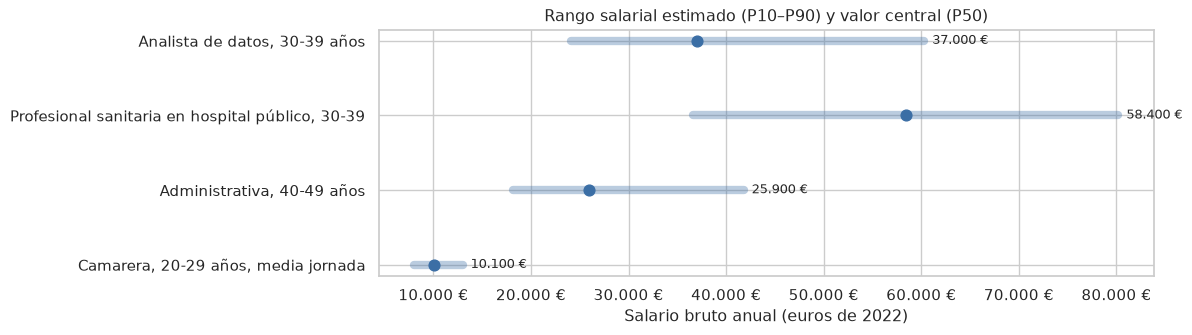

In [24]:
fig, ax = plt.subplots(figsize=(10, 3.2))
for i, (nombre, r) in enumerate(rangos.iterrows()):
    ax.plot([r["p10"], r["p90"]], [i, i], color=AZUL, lw=6, alpha=0.35, solid_capstyle="round")
    ax.scatter(r["p50"], i, color=AZUL, s=60, zorder=3)
    ax.text(r["p90"], i, f"  {r['p50']:,.0f} €".replace(",", "."), va="center", fontsize=9)
ax.set_yticks(range(len(rangos)), rangos.index)
ax.xaxis.set_major_formatter(EUROS)
ax.set(title="Rango salarial estimado (P10–P90) y valor central (P50)", xlabel="Salario bruto anual (euros de 2022)")
plt.show()

El rango de la profesional sanitaria es muy ancho y su valor central es alto: el grupo de ocupación del INE *Profesionales de la salud y la enseñanza* mezcla medicina, enfermería, farmacia y profesorado. Con solo 17 grandes grupos, el modelo no puede distinguir a una enfermera de una médica; el rango refleja precisamente esa incertidumbre. Es una **limitación de los datos** que se explicará en la web y en la memoria.

## 10. ¿Dónde se equivoca el modelo?

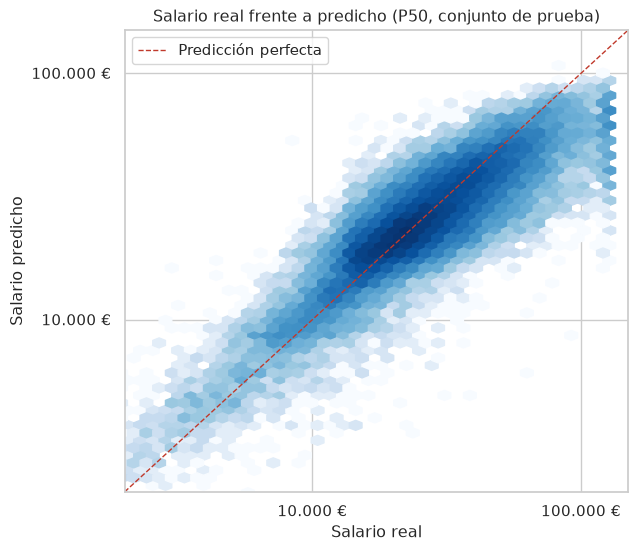

In [25]:
real = np.exp(y_test)
prediccion = np.exp(calibrado["p50"])
fig, ax = plt.subplots(figsize=(6.5, 6))
hb = ax.hexbin(real, prediccion, gridsize=60, xscale="log", yscale="log", bins="log", cmap="Blues", mincnt=1)
limites = [2_000, 150_000]
ax.plot(limites, limites, color=ROJO, lw=1, ls="--", label="Predicción perfecta")
ax.set(xlim=limites, ylim=limites, title="Salario real frente a predicho (P50, conjunto de prueba)",
       xlabel="Salario real", ylabel="Salario predicho")
ax.xaxis.set_major_formatter(EUROS); ax.yaxis.set_major_formatter(EUROS)
ax.legend()
plt.show()

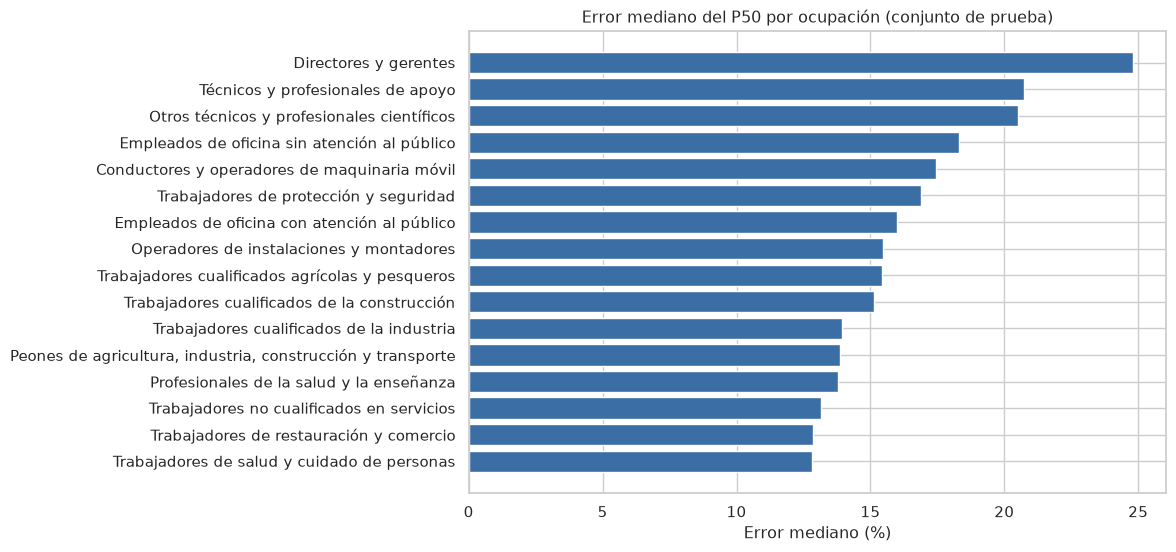

In [26]:
errores = test.assign(error_rel=np.abs(prediccion - real) / real)

def error_por(variable):
    return errores.groupby(variable, observed=True).apply(
        lambda g: pd.Series({"Registros": len(g),
                             "Error mediano (%)": 100 * float(cuantil_ponderado(g["error_rel"], g[PESO], 0.5))}),
        include_groups=False).sort_values("Error mediano (%)")

error_ocupacion = error_por("ocupacion")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(error_ocupacion.index, error_ocupacion["Error mediano (%)"], color=AZUL)
ax.set(title="Error mediano del P50 por ocupación (conjunto de prueba)", xlabel="Error mediano (%)")
plt.show()

In [27]:
error_por("jornada").round(1)

,Registros,Error mediano (%)
jornada,,
Tiempo completo,38163.0,15.8
Tiempo parcial,8605.0,16.4


- El modelo se equivoca **más en directivos y técnicos**, cuyos salarios dependen mucho de factores que la encuesta no recoge (responsabilidades concretas, empresa, negociación individual), y **menos en ocupaciones con salarios más homogéneos y muy marcados por convenio** (cuidados, restauración y comercio, servicios no cualificados).
- El error mediano es casi igual a tiempo completo que a tiempo parcial, porque la información de horas corrige la mayor parte de la diferencia.
- En los salarios más altos el modelo tiende a **quedarse corto**, y en los más bajos a pasarse: es el comportamiento normal de cualquier modelo, que tiende hacia los valores típicos. El rango P10–P90 compensa en parte este efecto.

## 11. Guardado del modelo final

In [28]:
carpeta = modelo_final.guardar()
for archivo in sorted(carpeta.iterdir()):
    print(f"{archivo.name:22s} {archivo.stat().st_size / 1e6:6.1f} MB")

.gitkeep                  0.0 MB
lgbm_p10.txt             11.1 MB
lgbm_p50.txt             11.0 MB
lgbm_p90.txt             11.0 MB
modelo_rango.json         0.0 MB


## 12. Conclusiones

1. **LightGBM es el mejor modelo** en todas las métricas, por delante de Random Forest y de la regresión lineal. Explica en torno al 80 % de la variabilidad del salario y reduce a la mitad el error de una regla basada solo en la ocupación.
2. **El ajuste de hiperparámetros apenas mejora el resultado.** El límite lo ponen los datos: hay factores que influyen en el salario y que la encuesta no recoge. Por eso el producto ofrece un **rango** y no una cifra.
3. **La evaluación es realista:** separar por empresa evita una evaluación demasiado optimista, que es lo que se obtiene al separar al azar.
4. **El formulario de la web puede ser más corto** (sin tipo de convenio ni mercado de la empresa) casi sin perder precisión.
5. **El rango salarial está calibrado:** gracias a la predicción conformal, el salario real cae dentro del rango P10–P90 en torno al 80 % de las veces, en empresas nuevas y de forma bastante homogénea entre ocupaciones.
6. **El modelo se equivoca más** en directivos y técnicos (salarios muy individualizados) y menos en las ocupaciones reguladas por convenio. La principal limitación de los datos es que las 17 grandes ocupaciones agrupan profesiones muy distintas (por ejemplo, medicina y enfermería).

**Siguientes pasos**
- **Notebook 05:** entender *por qué* el modelo da cada predicción (SHAP), detectar sesgos y estimar la brecha salarial de género ajustada.
- **Notebook 06:** validación temporal (¿sirve un modelo de 2018 para 2022?) y monitorización.